In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random

In [2]:
env = gym.make('FrozenLake-v1')

actions = range(env.action_space.n)

num_episodes = 10000
nul_eval_episodes = 100

alpha = 0.1
gamma = 0.99
epsilon = 1
min_epsilon = 0.01
decay_rate = 0.9995

episode_rewards = np.zeros(num_episodes)
eval_episode_rewards = np.zeros(nul_eval_episodes)

#dql class functions and intializations

In [3]:
class DoubleQLearning:
    def __init__(self, alpha, gamma, epsilon, actions):
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.actions = list(actions)
        self.q1 = {}
        self.q2 = {}
        self.state = None
        self.action = None

    def update(self, reward, next_state, done):
        if random.random() < 0.5:
            best_next_a = self._argmax(self.q1, next_state)
            future_q = 0 if done else self.q2.get((next_state, best_next_a), 0)
            td_target = reward + self.gamma * future_q
            self.q1[(self.state, self.action)] = self.q1.get((self.state, self.action), 0) + self.alpha * (td_target - self.q1.get((self.state, self.action), 0))
        else:
            best_next_a = self._argmax(self.q2, next_state)
            future_q = 0 if done else self.q1.get((next_state, best_next_a), 0)
            td_target = reward + self.gamma * future_q
            self.q2[(self.state, self.action)] = self.q2.get((self.state, self.action), 0) + self.alpha * (td_target - self.q2.get((self.state, self.action), 0))

    def act(self, state, eval_mode=False):
        self.state = state
        if not eval_mode and random.random() < self.epsilon:
            self.action = random.choice(self.actions)
        else:
            q_sum = {a: self.q1.get((state, a), 0) + self.q2.get((state, a), 0) for a in self.actions}
            max_val = max(q_sum.values())
            best_actions = [a for a, v in q_sum.items() if v == max_val]
            self.action = random.choice(best_actions)
        return self.action

    def _argmax(self, d, state):
        values = {a: d.get((state, a), 0) for a in self.actions}
        max_val = max(values.values())
        best_actions = [a for a, v in values.items() if v == max_val]
        return random.choice(best_actions)

In [4]:
agent = DoubleQLearning(alpha, gamma, epsilon, actions)

#training the agent

In [5]:
for i in range(num_episodes):
    state, info = env.reset()
    done = False
    episode_reward = 0
    agent.epsilon = epsilon

    while not done:
        action = agent.act(state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        agent.update(reward, next_state, done)
        episode_reward += reward
        state = next_state

    episode_rewards[i] = episode_reward
    epsilon = max(min_epsilon, epsilon * decay_rate)

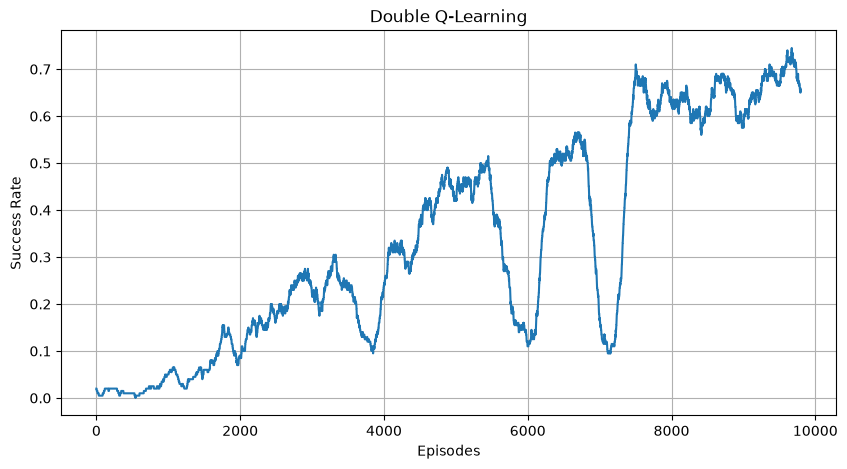

In [6]:
window = 200
moving_avg = np.convolve(episode_rewards, np.ones(window)/window, mode='valid')

plt.figure(figsize=(10, 5))
plt.plot(moving_avg)
plt.title(f'Double Q-Learning')
plt.xlabel('Episodes')
plt.ylabel('Success Rate')
plt.grid(True)
plt.show()

#evaluation

In [7]:
for i in range(nul_eval_episodes):
    state, info = env.reset()
    done = False
    eval_episode_reward = 0

    while not done:
        action = agent.act(state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        eval_episode_reward += reward
        state = next_state
    eval_episode_rewards[i] = eval_episode_reward

print("Average evaluation episode reward: {}".format(np.mean(eval_episode_rewards)))

Average evaluation episode reward: 0.73
